In [ ]:
#Men's Sports Shoes Web Scraping — Snapdeal

In [1]:
%pip install requests beautifulsoup4 pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:

import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time

# 1. Website URL
URL = "https://www.snapdeal.com/products/mens-footwear-sports-shoes"

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/131.0.0.0 Safari/537.36"
    )
}

products = []

# 2. Scrape product listing pages
for page in range(1, 4):
    page_url = f"{URL}?sort=plrty&page={page}"

    try:
        response = requests.get(
            page_url, headers=HEADERS, timeout=20
        )
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Find product cards
        cards = soup.select("div.product-tuple-listing")

        if not cards:
            print("No product cards found on page", page)
            print("The website may have changed its HTML.")
            break

        for card in cards:
            # Product name
            name_tag = card.select_one("p.product-title")
            product_name = (
                name_tag.get_text(" ", strip=True)
                if name_tag else "Not Available"
            )

            # Brand: use the first word as a basic estimate
            brand = (
                product_name.split()[0]
                if product_name != "Not Available"
                else "Not Available"
            )

            # Discounted price
            price_tag = card.select_one("span.product-price")
            discounted_price = None

            if price_tag:
                price_text = price_tag.get_text(" ", strip=True)
                match = re.search(r"[\d,]+(?:\.\d+)?", price_text)
                if match:
                    discounted_price = float(
                        match.group().replace(",", "")
                    )

            # Original price
            original_tag = card.select_one(
                "span.product-desc-price"
            )
            original_price = None

            if original_tag:
                match = re.search(
                    r"[\d,]+(?:\.\d+)?",
                    original_tag.get_text(" ", strip=True)
                )
                if match:
                    original_price = float(
                        match.group().replace(",", "")
                    )

            # Discount percentage
            discount_tag = card.select_one("div.product-discount")
            discount_pct = None

            if discount_tag:
                match = re.search(
                    r"(\d+(?:\.\d+)?)\s*%",
                    discount_tag.get_text(" ", strip=True)
                )
                if match:
                    discount_pct = float(match.group(1))

            # Calculate discount if it is not displayed
            if (
                discount_pct is None
                and original_price is not None
                and discounted_price is not None
                and original_price > 0
            ):
                discount_pct = round(
                    (original_price - discounted_price)
                    / original_price * 100,
                    2
                )

            # Rating
            rating_tag = card.select_one(
                "div.product-desc-rating"
            )
            rating = None

            if rating_tag:
                match = re.search(
                    r"\d+(?:\.\d+)?",
                    rating_tag.get_text(" ", strip=True)
                )
                if match:
                    rating = float(match.group())

            # Number of reviews/ratings
            reviews_tag = card.select_one(
                "p.product-rating-count"
            )
            review_count = None

            if reviews_tag:
                match = re.search(
                    r"[\d,]+",
                    reviews_tag.get_text(" ", strip=True)
                )
                if match:
                    review_count = int(
                        match.group().replace(",", "")
                    )

            products.append({
                "Product Name": product_name,
                "Brand": brand,
                "Original Price": original_price,
                "Discounted Price": discounted_price,
                "Discount Percentage": discount_pct,
                "Rating": rating,
                "Number of Reviews": review_count
            })

        print(f"Page {page}: {len(cards)} products found")
        time.sleep(2)

    except requests.RequestException as error:
        print(f"Error on page {page}: {error}")
        break

# 3. Create a DataFrame
df = pd.DataFrame(products)

# 4. Remove duplicate products
if not df.empty:
    df.drop_duplicates(
        subset=["Product Name"],
        inplace=True
    )

    # 5. Save data to CSV
    df.to_csv(
        "snapdeal_mens_sports_shoes.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nScraping completed!")
    print("Total products collected:", len(df))
    print(df.head())
    print("\nCSV file saved successfully.")

else:
    print(
        "No data collected. Check the URL, website access, "
        "and HTML selectors."
    )


Page 1: 20 products found
Page 2: 20 products found
Page 3: 20 products found

Scraping completed!
Total products collected: 37
                                        Product Name   Brand  Original Price  \
0      Campus DRIVO White Men's Sports Running Shoes  Campus          2499.0   
1  ASIAN WONDER-14 Dark Grey Men's Sports Running...   ASIAN          1299.0   
2        Clymb Light Grey Men's Sports Running Shoes   Clymb           999.0   
3  Campus NORTH PLUS Black Men's Sports Running S...  Campus          1899.0   
4    ASIAN Future-04 Blue Men's Sports Running Shoes   ASIAN           999.0   

   Discounted Price  Discount Percentage  Rating  Number of Reviews  
0             987.0                 61.0     2.0                451  
1             441.0                 66.0    14.0                 89  
2             434.0                 57.0   999.0                193  
3             847.0                 55.0     1.0               2163  
4             546.0                 45.0 

Top Brands:
Brand
Campus       12
ASIAN        12
DUCKINS       5
Clymb         3
hotstyle      1
Richerson     1
JK            1
JQR           1
RRVOX         1
Name: count, dtype: int64
Average Discounted Price: 700.5135135135135
Average Discount: 61.270270270270274


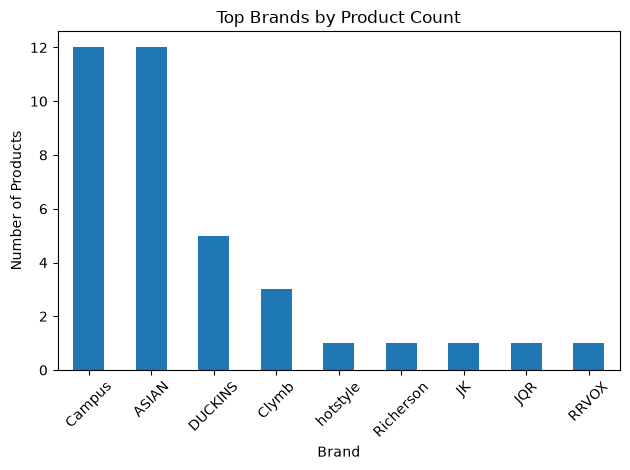

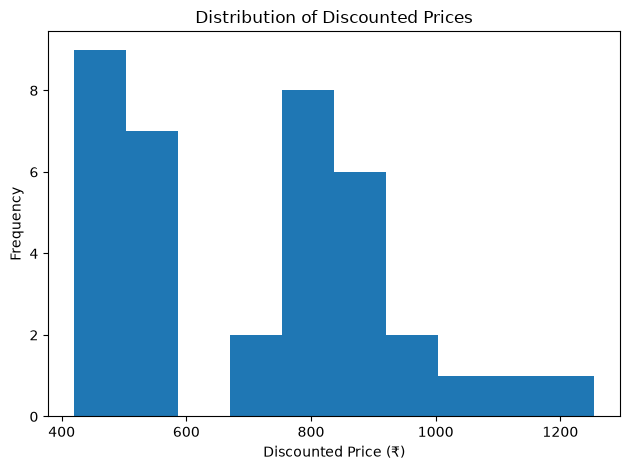

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("snapdeal_mens_sports_shoes.csv")

# 1. Top brands by product count
print("Top Brands:")
print(df["Brand"].value_counts().head(10))

# 2. Average discounted price
print(
    "Average Discounted Price:",
    df["Discounted Price"].mean()
)

# 3. Average discount percentage
print(
    "Average Discount:",
    df["Discount Percentage"].mean()
)

# 4. Plot top brands
df["Brand"].value_counts().head(10).plot(
    kind="bar",
    title="Top Brands by Product Count"
)
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Price distribution
df["Discounted Price"].dropna().plot(
    kind="hist",
    bins=10,
    title="Distribution of Discounted Prices"
)
plt.xlabel("Discounted Price (₹)")
plt.tight_layout()
plt.show()
